In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Dual-Channel Heart Disease Prediction
Channel 1: SVM + XGBoost (demographic/lab) | Channel 2: Attention-DNN (clinical/ECG) | Fusion: stacking meta-learner

## Step 1 — Setup & configuration

In [1]:
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)
from xgboost import XGBClassifier

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping

# ---------------- configuration ----------------
DATA_PATH  = "/kaggle/input/datasets/redwankarimsony/heart-disease-data/heart_disease_uci.csv"
OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
SEED       = 42

RUN_ABLATION  = True    # Step 8
RUN_TUNING    = True    # Step 9
RUN_NESTED_CV = True    # Step 12  (slowest: ~25 DNN trainings)
RUN_SHAP      = True    # Step 13

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print("Setup complete. Output dir:", OUTPUT_DIR.resolve())

I0000 00:00:1794077720.684012      49 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794077740.579065      49 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Setup complete. Output dir: /kaggle/working


## Step 2 — Data loading

In [6]:
import os
for root, _, files in os.walk("/kaggle/input"):
    for f in files:
        print(os.path.join(root, f))

/kaggle/input/datasets/redwankarimsony/heart-disease-data/heart_disease_uci.csv


In [11]:
df = pd.read_csv("/kaggle/input/datasets/redwankarimsony/heart-disease-data/heart_disease_uci.csv")
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (920, 16)


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


## Step 3 — Exploratory data analysis & data-quality audit

In [12]:
# 3.1 Structure and missing values
df.info()
missing = df.isna().sum().to_frame("missing")
missing["percent"] = (missing["missing"] / len(df) * 100).round(1)
print("\nMissing values:")
display(missing[missing["missing"] > 0].sort_values("missing", ascending=False))

# 3.2 Duplicates
feature_cols = [c for c in df.columns if c not in ("id", "dataset", "num")]
print("Exact duplicate rows            :", df.duplicated().sum())
print("Duplicate rows (features only)  :", df[feature_cols].duplicated().sum())

# 3.3 Physiologically suspicious zeros (kept deliberately, see Step 8)
print("\nchol == 0     :", int((df["chol"] == 0).sum()))
print("trestbps == 0 :", int((df["trestbps"] == 0).sum()))

# 3.4 IQR outlier flags (flagged only, nothing is removed)
num_cols_eda = ["age", "trestbps", "chol", "thalch", "oldpeak"]
rows = []
for c in num_cols_eda:
    s = df[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    rows.append({"feature": c, "outliers": int(((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum())})
print("\nPotential outliers (IQR rule):")
display(pd.DataFrame(rows))

# 3.5 Data sources
print("\nRecords per source:")
display(df["dataset"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB

Missing values:


,missing,percent
ca,611,66.4
thal,486,52.8
slope,309,33.6
fbs,90,9.8
oldpeak,62,6.7
trestbps,59,6.4
exang,55,6.0
thalch,55,6.0
chol,30,3.3
restecg,2,0.2


Exact duplicate rows            : 0
Duplicate rows (features only)  : 2

chol == 0     : 172
trestbps == 0 : 1

Potential outliers (IQR rule):


,feature,outliers
0,age,0
1,trestbps,28
2,chol,183
3,thalch,2
4,oldpeak,16



Records per source:


dataset
Cleveland        304
Hungary          293
VA Long Beach    200
Switzerland      123
Name: count, dtype: int64

## Step 4 — Target definition & feature matrix

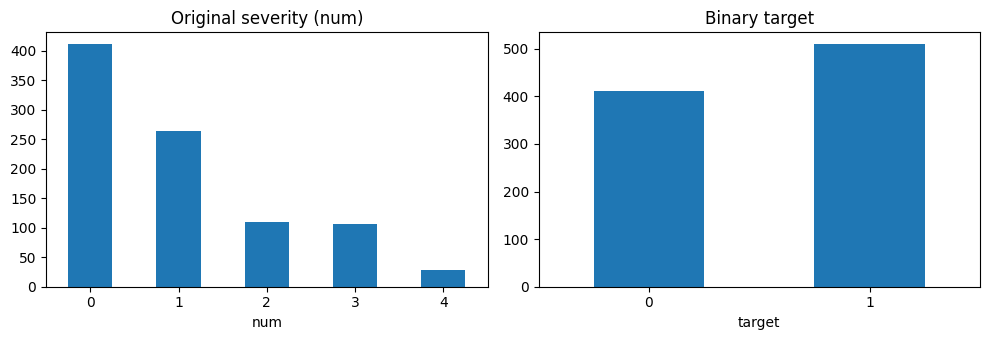

Target distribution:
 target
0    411
1    509
Name: count, dtype: int64

Target rate by source:


target,0,1
dataset,,
Cleveland,0.543,0.457
Hungary,0.638,0.362
Switzerland,0.065,0.935
VA Long Beach,0.255,0.745



Feature matrix: (920, 13) | Target: (920,)


In [13]:
# Binary target: 0 = no heart disease, 1 = heart disease present (num > 0)
df["target"] = (df["num"] > 0).astype(int)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
df["num"].value_counts().sort_index().plot(kind="bar", rot=0, ax=ax[0], title="Original severity (num)")
df["target"].value_counts().sort_index().plot(kind="bar", rot=0, ax=ax[1], title="Binary target")
plt.tight_layout(); plt.show()

print("Target distribution:\n", df["target"].value_counts().sort_index())
print("\nTarget rate by source:")
display(pd.crosstab(df["dataset"], df["target"], normalize="index").round(3))

# id, dataset and the original label are not input features
X = df.drop(columns=["id", "dataset", "num", "target"])
y = df["target"]
print("\nFeature matrix:", X.shape, "| Target:", y.shape)

## Step 5 — Train / test split
Split is done before any fitting, so the test set stays untouched (no data leakage).

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train class counts:", y_train.value_counts().sort_index().to_dict())
print("Test  class counts:", y_test.value_counts().sort_index().to_dict())

CV      = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"accuracy": "accuracy", "precision": "precision", "recall": "recall",
           "f1": "f1", "roc_auc": "roc_auc"}

Train: (736, 13) | Test: (184, 13)
Train class counts: {0: 329, 1: 407}
Test  class counts: {0: 82, 1: 102}


## Step 6 — Preprocessing design
* Numeric (age, trestbps, chol, thalch, oldpeak): median imputation → standard scaling
* Categorical: missing → "Missing" category → one-hot. `ca` is categorical.
* chol == 0 is kept as is
* Channel 1: age, sex, trestbps, chol, fbs, thalch
* Channel 2: cp, restecg, exang, oldpeak, slope, ca, thal

In [16]:
def _to_str(X):
    return np.asarray(X).astype(str)

def _zero_to_nan(X, idx):
    X = np.asarray(X, dtype=float).copy()
    X[X[:, idx] == 0, idx] = np.nan
    return X

def make_preprocessor(num_cols, cat_cols, cat_strategy="constant",
                      chol_zero_to_nan=False, add_indicator=False):
    # Build a ColumnTransformer. Defaults give the final preprocessing used in the paper.
    num_steps = []
    if chol_zero_to_nan and "chol" in num_cols:
        num_steps.append(("chol_zero", FunctionTransformer(_zero_to_nan,
                          kw_args={"idx": num_cols.index("chol")})))
    num_steps += [("imputer", SimpleImputer(strategy="median", add_indicator=add_indicator)),
                  ("scaler", StandardScaler())]

    if cat_strategy == "constant":
        cat_imputer = SimpleImputer(strategy="constant", fill_value="Missing")
    else:
        cat_imputer = SimpleImputer(strategy="most_frequent")
    cat_pipe = Pipeline([("imputer", cat_imputer),
                         ("to_str", FunctionTransformer(_to_str)),
                         ("encoder", OneHotEncoder(handle_unknown="ignore"))])

    transformers = []
    if num_cols: transformers.append(("num", Pipeline(num_steps), list(num_cols)))
    if cat_cols: transformers.append(("cat", cat_pipe, list(cat_cols)))
    return ColumnTransformer(transformers)

def get_feature_names(pre, num_cols, cat_cols):
    enc = pre.named_transformers_["cat"].named_steps["encoder"]
    return list(num_cols) + enc.get_feature_names_out(cat_cols).tolist()

# ---- feature groups ----
NUM_ALL = ["age", "trestbps", "chol", "thalch", "oldpeak"]
CAT_ALL = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

CH1_FEATURES = ["age", "sex", "trestbps", "chol", "fbs", "thalch"]
CH2_FEATURES = ["cp", "restecg", "exang", "oldpeak", "slope", "ca", "thal"]
CH1_NUM = [c for c in CH1_FEATURES if c in NUM_ALL]
CH1_CAT = [c for c in CH1_FEATURES if c in CAT_ALL]
CH2_NUM = [c for c in CH2_FEATURES if c in NUM_ALL]
CH2_CAT = [c for c in CH2_FEATURES if c in CAT_ALL]

assert sorted(CH1_FEATURES + CH2_FEATURES) == sorted(X.columns), "every feature must be used exactly once"
print("Channel 1 -> numeric:", CH1_NUM, "| categorical:", CH1_CAT)
print("Channel 2 -> numeric:", CH2_NUM, "| categorical:", CH2_CAT)

# sanity check: the pipeline is fitted on train only, and leaves no NaN
_pre = make_preprocessor(NUM_ALL, CAT_ALL)
_tr = _pre.fit_transform(X_train); _te = _pre.transform(X_test)
print("Processed train/test shapes:", _tr.shape, _te.shape)

Channel 1 -> numeric: ['age', 'trestbps', 'chol', 'thalch'] | categorical: ['sex', 'fbs']
Channel 2 -> numeric: ['oldpeak'] | categorical: ['cp', 'restecg', 'exang', 'slope', 'ca', 'thal']
Processed train/test shapes: (736, 33) (184, 33)


## Step 7 — Baseline models

In [17]:
BASELINES = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "KNN (k=5)":           KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)":           SVC(kernel="rbf", probability=True, random_state=SEED),
    "Decision Tree":       DecisionTreeClassifier(random_state=SEED),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1),
    "XGBoost":             XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05,
                                         random_state=SEED, eval_metric="logloss", n_jobs=1),
}
baseline_pipes = {name: Pipeline([("preprocessor", make_preprocessor(NUM_ALL, CAT_ALL)), ("model", m)])
                  for name, m in BASELINES.items()}

def cv_report(models, X_, y_):
    rows = []
    for name, model in models.items():
        s = cross_validate(model, X_, y_, cv=CV, scoring=SCORING, n_jobs=-1)
        row = {"Model": name}
        for m in SCORING:
            row[m] = f"{s['test_' + m].mean():.4f} ± {s['test_' + m].std():.4f}"
        rows.append(row)
    return pd.DataFrame(rows)

baseline_cv = cv_report(baseline_pipes, X_train, y_train)
print("Baselines — 5-fold CV on training data")
display(baseline_cv)

Baselines — 5-fold CV on training data


,Model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.8180 ± 0.0180,0.8317 ± 0.0372,0.8451 ± 0.0235,0.8373 ± 0.0107,0.8957 ± 0.0230
1,KNN (k=5),0.8275 ± 0.0350,0.8332 ± 0.0387,0.8624 ± 0.0283,0.8472 ± 0.0291,0.8765 ± 0.0327
2,SVM (RBF),0.8356 ± 0.0261,0.8310 ± 0.0339,0.8845 ± 0.0098,0.8566 ± 0.0194,0.8981 ± 0.0246
3,Decision Tree,0.7283 ± 0.0335,0.7416 ± 0.0341,0.7839 ± 0.0288,0.7617 ± 0.0257,0.7215 ± 0.0363
4,Random Forest,0.8125 ± 0.0176,0.8197 ± 0.0300,0.8500 ± 0.0150,0.8340 ± 0.0113,0.8807 ± 0.0246
5,XGBoost,0.8031 ± 0.0440,0.8106 ± 0.0519,0.8452 ± 0.0305,0.8267 ± 0.0348,0.8736 ± 0.0274


## Step 8 — Preprocessing ablation study

In [18]:
if RUN_ABLATION:
    NUM_WITH_CA = NUM_ALL + ["ca"]
    CAT_NO_CA   = [c for c in CAT_ALL if c != "ca"]
    configs = {
        "A. ca numeric + mode imputation":            dict(num_cols=NUM_WITH_CA, cat_cols=CAT_NO_CA, cat_strategy="most_frequent"),
        "B. ca categorical + mode imputation":        dict(num_cols=NUM_ALL, cat_cols=CAT_ALL, cat_strategy="most_frequent"),
        "C. B + 'Missing' category  (FINAL)":         dict(num_cols=NUM_ALL, cat_cols=CAT_ALL, cat_strategy="constant"),
        "D. C + chol=0 treated as missing":           dict(num_cols=NUM_ALL, cat_cols=CAT_ALL, cat_strategy="constant", chol_zero_to_nan=True),
        "E. D + missing-value indicators":            dict(num_cols=NUM_ALL, cat_cols=CAT_ALL, cat_strategy="constant", chol_zero_to_nan=True, add_indicator=True),
    }
    ablation_pipes = {name: Pipeline([("preprocessor", make_preprocessor(**cfg)),
                                      ("model", SVC(kernel="rbf", probability=True, random_state=SEED))])
                      for name, cfg in configs.items()}
    ablation_df = cv_report(ablation_pipes, X_train, y_train)
    display(ablation_df)
else:
    print("Ablation skipped.")

,Model,accuracy,precision,recall,f1,roc_auc
0,A. ca numeric + mode imputation,0.8220 ± 0.0328,0.8249 ± 0.0506,0.8672 ± 0.0308,0.8441 ± 0.0245,0.8908 ± 0.0229
1,B. ca categorical + mode imputation,0.8288 ± 0.0301,0.8314 ± 0.0496,0.8721 ± 0.0218,0.8500 ± 0.0212,0.8933 ± 0.0235
2,C. B + 'Missing' category (FINAL),0.8356 ± 0.0261,0.8310 ± 0.0339,0.8845 ± 0.0098,0.8566 ± 0.0194,0.8981 ± 0.0246
3,D. C + chol=0 treated as missing,0.8370 ± 0.0266,0.8343 ± 0.0426,0.8844 ± 0.0172,0.8578 ± 0.0188,0.8941 ± 0.0268
4,E. D + missing-value indicators,0.8166 ± 0.0292,0.8100 ± 0.0391,0.8771 ± 0.0222,0.8415 ± 0.0214,0.8920 ± 0.0249


## Step 9 — Hyper-parameter tuning (SVM)

In [19]:
if RUN_TUNING:
    svm_search = GridSearchCV(
        Pipeline([("preprocessor", make_preprocessor(NUM_ALL, CAT_ALL)),
                  ("model", SVC(kernel="rbf", probability=True, random_state=SEED))]),
        param_grid={"model__C": [0.1, 1, 10, 100],
                    "model__gamma": ["scale", 0.001, 0.01, 0.1, 1]},
        scoring="roc_auc", cv=CV, n_jobs=-1, refit=True)
    svm_search.fit(X_train, y_train)
    print("Best parameters   :", svm_search.best_params_)
    print("Best CV ROC-AUC   :", round(svm_search.best_score_, 4))
else:
    print("Tuning skipped.")

# The dual-channel model below uses the selected setting (C=1, gamma='scale').
SVM_PARAMS = dict(kernel="rbf", C=1, gamma="scale", probability=True, random_state=SEED)

Best parameters   : {'model__C': 1, 'model__gamma': 'scale'}
Best CV ROC-AUC   : 0.8981


## Step 10 — Proposed dual-channel model
1. Channel 1: SVM + XGBoost soft voting
2. Channel 2: attention-gated DNN
3. Fusion: logistic-regression meta-learner on 5-fold out-of-fold probabilities
4. Both channels refit on full training set; meta-learner fuses test probabilities

In [20]:
# ---------------- Channel 1 ----------------
def make_channel1_model():
    pre = make_preprocessor(CH1_NUM, CH1_CAT)
    svm = Pipeline([("preprocessor", clone(pre)), ("model", SVC(**SVM_PARAMS))])
    xgb = Pipeline([("preprocessor", clone(pre)),
                    ("model", XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05,
                                            random_state=SEED, eval_metric="logloss"))])
    return VotingClassifier([("svm", svm), ("xgb", xgb)], voting="soft", weights=[1, 1])

# ---------------- Channel 2 ----------------
def build_attention_dnn(input_dim):
    inputs    = layers.Input(shape=(input_dim,), name="channel2_input")
    attention = layers.Dense(input_dim, activation="sigmoid", name="feature_attention")(inputs)
    attended  = layers.Multiply(name="attention_gating")([inputs, attention])
    x = layers.Dense(32, activation="relu")(attended)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(16, activation="relu")(x)
    outputs = layers.Dense(1, activation="sigmoid", name="prediction")(x)
    model = Model(inputs, outputs)
    model.compile(optimizer="adam", loss="binary_crossentropy",
                  metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy"),
                           tf.keras.metrics.AUC(name="auc")])
    return model

def prepare_ch2(X_fit, X_other):
    # Fit the Channel-2 preprocessor on X_fit only; return dense float32 arrays.
    pre = make_preprocessor(CH2_NUM, CH2_CAT)
    A = pre.fit_transform(X_fit); B = pre.transform(X_other)
    A = A.toarray() if hasattr(A, "toarray") else A
    B = B.toarray() if hasattr(B, "toarray") else B
    return np.asarray(A, dtype=np.float32), np.asarray(B, dtype=np.float32), pre

def train_dnn(X_fit, y_fit, X_stop, y_stop, tf_seed):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(tf_seed)
    model = build_attention_dnn(X_fit.shape[1])
    model.fit(X_fit, y_fit, validation_data=(X_stop, y_stop), epochs=100, batch_size=32,
              callbacks=[EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)],
              verbose=0)
    return model

# ---------------- Stacked fusion ----------------
def dual_channel_predict(X_tr, y_tr, X_ev, n_inner=5, oof_mode="val_fold", oof_seed=100,
                         final_split_seed=42, final_tf_seed=142):
    # oof_mode = 'val_fold' : the OOF fold itself is the DNN early-stopping set (main experiment)
    # oof_mode = 'holdout'  : 15% of the inner-train part is used for early stopping (leak-free; nested CV)
    skf  = StratifiedKFold(n_splits=n_inner, shuffle=True, random_state=SEED)
    oof1 = np.zeros(len(X_tr)); oof2 = np.zeros(len(X_tr))

    for fold, (tr, va) in enumerate(skf.split(X_tr, y_tr), start=1):
        Xtr, Xva = X_tr.iloc[tr], X_tr.iloc[va]
        ytr, yva = y_tr.iloc[tr], y_tr.iloc[va]

        c1 = make_channel1_model().fit(Xtr[CH1_FEATURES], ytr)
        oof1[va] = c1.predict_proba(Xva[CH1_FEATURES])[:, 1]

        Xf, Xv, _ = prepare_ch2(Xtr[CH2_FEATURES], Xva[CH2_FEATURES])
        if oof_mode == "val_fold":
            Xfit, yfit, Xstop, ystop = Xf, ytr.to_numpy(), Xv, yva.to_numpy()
        else:
            Xfit, Xstop, yfit, ystop = train_test_split(
                Xf, ytr.to_numpy(), test_size=0.15, random_state=oof_seed + fold, stratify=ytr)
        dnn = train_dnn(Xfit, yfit, Xstop, ystop, oof_seed + fold)
        oof2[va] = dnn.predict(Xv, verbose=0).ravel()

    meta = LogisticRegression(max_iter=1000, random_state=SEED).fit(np.column_stack([oof1, oof2]), y_tr)

    # refit both channels on the whole training part
    ch1 = make_channel1_model().fit(X_tr[CH1_FEATURES], y_tr)
    p1  = ch1.predict_proba(X_ev[CH1_FEATURES])[:, 1]

    Xall, Xev2, ch2_pre = prepare_ch2(X_tr[CH2_FEATURES], X_ev[CH2_FEATURES])
    Xfit, Xstop, yfit, ystop = train_test_split(
        Xall, y_tr.to_numpy(), test_size=0.15, random_state=final_split_seed, stratify=y_tr)
    ch2 = train_dnn(Xfit, yfit, Xstop, ystop, final_tf_seed)
    p2  = ch2.predict(Xev2, verbose=0).ravel()

    fused = meta.predict_proba(np.column_stack([p1, p2]))[:, 1]
    return dict(p1=p1, p2=p2, fused=fused, meta=meta, ch1=ch1, ch2=ch2,
                ch2_pre=ch2_pre, ch2_train_processed=Xall)

main = dual_channel_predict(X_train, y_train, X_test)       # headline experiment
print("Meta-learner weights  ->  Channel 1: %.3f | Channel 2: %.3f | intercept: %.3f"
      % (main["meta"].coef_[0][0], main["meta"].coef_[0][1], main["meta"].intercept_[0]))

E0000 00:00:1794078503.672754      49 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Meta-learner weights  ->  Channel 1: 2.123 | Channel 2: 4.069 | intercept: -3.157


## Step 11 — Final test-set evaluation

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.8370,0.8333,0.8824,0.8571,0.9212
1,KNN (k=5),0.8424,0.8476,0.8725,0.8599,0.8997
2,SVM (RBF),0.8587,0.8393,0.9216,0.8785,0.9188
3,Decision Tree,0.7554,0.7664,0.8039,0.7847,0.7495
4,Random Forest,0.8315,0.8257,0.8824,0.8531,0.9252
5,XGBoost,0.8478,0.8558,0.8725,0.8641,0.9065
6,Channel 1: SVM + XGBoost,0.7826,0.7818,0.8431,0.8113,0.8027
7,Channel 2: Attention DNN,0.8315,0.8381,0.8627,0.8502,0.9118
8,Dual-Channel Fusion (proposed),0.8750,0.8435,0.9510,0.8940,0.9139



DUAL-CHANNEL FUSION — TEST SET
Accuracy : 0.8750
Recall   : 0.9510

Confusion matrix:
 [[64 18]
 [ 5 97]]

               precision    recall  f1-score   support

           0       0.93      0.78      0.85        82
           1       0.84      0.95      0.89       102

    accuracy                           0.88       184
   macro avg       0.89      0.87      0.87       184
weighted avg       0.88      0.88      0.87       184



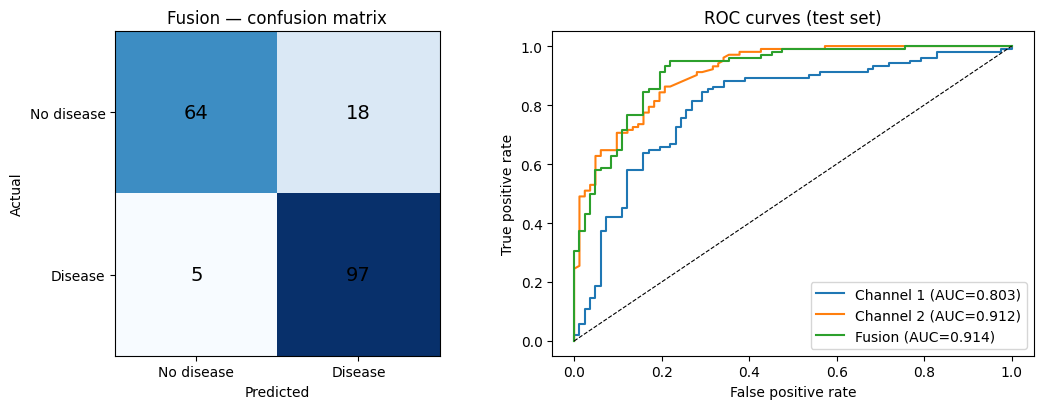

In [21]:
def metrics_row(name, y_true, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {"Model": name,
            "Accuracy":  accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred, zero_division=0),
            "Recall":    recall_score(y_true, pred, zero_division=0),
            "F1-score":  f1_score(y_true, pred, zero_division=0),
            "ROC-AUC":   roc_auc_score(y_true, prob)}

y_true = np.asarray(y_test)
rows = []

# baselines (fit on train, evaluated once on the untouched test set)
for name, pipe in baseline_pipes.items():
    pipe.fit(X_train, y_train)
    rows.append(metrics_row(name, y_true, pipe.predict_proba(X_test)[:, 1]))

rows += [metrics_row("Channel 1: SVM + XGBoost", y_true, main["p1"]),
         metrics_row("Channel 2: Attention DNN",  y_true, main["p2"]),
         metrics_row("Dual-Channel Fusion (proposed)", y_true, main["fused"])]

test_results = pd.DataFrame(rows)
display(test_results.round(4))

fusion_pred = (main["fused"] >= 0.5).astype(int)
print("\nDUAL-CHANNEL FUSION — TEST SET")
print("Accuracy : %.4f" % accuracy_score(y_true, fusion_pred))
print("Recall   : %.4f" % recall_score(y_true, fusion_pred))
print("\nConfusion matrix:\n", confusion_matrix(y_true, fusion_pred))
print("\n", classification_report(y_true, fusion_pred, zero_division=0))

# confusion matrix + ROC curves
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
cm = confusion_matrix(y_true, fusion_pred)
ax[0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
ax[0].set_xticks([0, 1]); ax[0].set_yticks([0, 1])
ax[0].set_xticklabels(["No disease", "Disease"]); ax[0].set_yticklabels(["No disease", "Disease"])
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual"); ax[0].set_title("Fusion — confusion matrix")

for label, p in [("Channel 1", main["p1"]), ("Channel 2", main["p2"]), ("Fusion", main["fused"])]:
    fpr, tpr, _ = roc_curve(y_true, p)
    ax[1].plot(fpr, tpr, label=f"{label} (AUC={roc_auc_score(y_true, p):.3f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
ax[1].set_title("ROC curves (test set)"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "final_evaluation.png", dpi=300, bbox_inches="tight"); plt.show()

## Step 12 — Robust evaluation: nested cross-validation
Whole stacking pipeline re-run inside 5 outer folds of the training data (leak-free mean ± std).

In [22]:
if RUN_NESTED_CV:
    outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)
    nested_rows = []
    for k, (tr, va) in enumerate(outer.split(X_train, y_train), start=1):
        print(f"Outer fold {k}/5 ...")
        out = dual_channel_predict(X_train.iloc[tr], y_train.iloc[tr], X_train.iloc[va],
                                   n_inner=4, oof_mode="holdout", oof_seed=100 * k,
                                   final_split_seed=500 + k, final_tf_seed=500 + k)
        r = metrics_row(f"Fold {k}", y_train.iloc[va].to_numpy(), out["fused"])
        nested_rows.append(r)

    nested_df = pd.DataFrame(nested_rows).set_index("Model")
    display(nested_df.round(4))
    summary = pd.DataFrame({"Mean": nested_df.mean(), "Std": nested_df.std(ddof=1)})
    summary["Mean ± Std"] = summary.apply(lambda r: f"{r.Mean:.4f} ± {r.Std:.4f}", axis=1)
    print("Nested CV summary:")
    display(summary.round(4))
else:
    print("Nested CV skipped.")

Outer fold 1/5 ...
Outer fold 2/5 ...
Outer fold 3/5 ...
Outer fold 4/5 ...
Outer fold 5/5 ...


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Fold 1,0.7770,0.7692,0.8537,0.8092,0.8594
Fold 2,0.8503,0.8571,0.8780,0.8675,0.9272
Fold 3,0.8231,0.8395,0.8395,0.8395,0.8724
Fold 4,0.8163,0.8068,0.8765,0.8402,0.8629
Fold 5,0.8776,0.8889,0.8889,0.8889,0.9136


Nested CV summary:


,Mean,Std,Mean ± Std
Accuracy,0.8289,0.0378,0.8289 ± 0.0378
Precision,0.8323,0.0461,0.8323 ± 0.0461
Recall,0.8673,0.0202,0.8673 ± 0.0202
F1-score,0.8491,0.0303,0.8491 ± 0.0303
ROC-AUC,0.8871,0.0311,0.8871 ± 0.0311


## Step 13 — Explainability (SHAP)
Channel 2 is explained with the trained final DNN (main["ch2"]).

  0%|          | 0/20 [00:00<?, ?it/s]

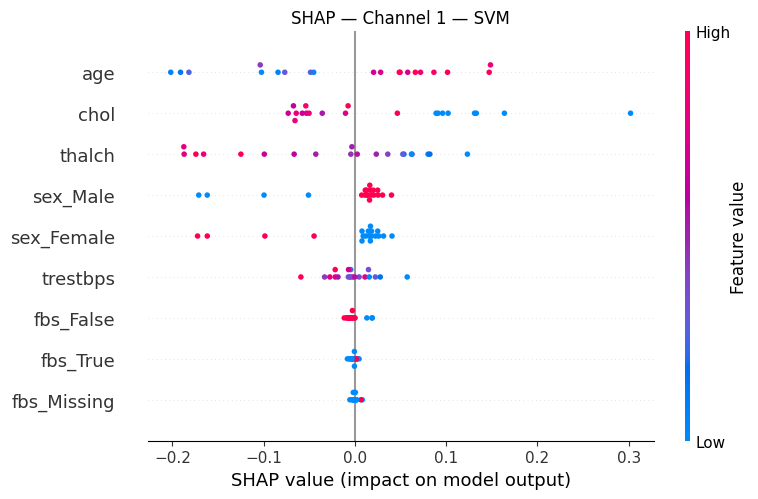

  0%|          | 0/20 [00:00<?, ?it/s]

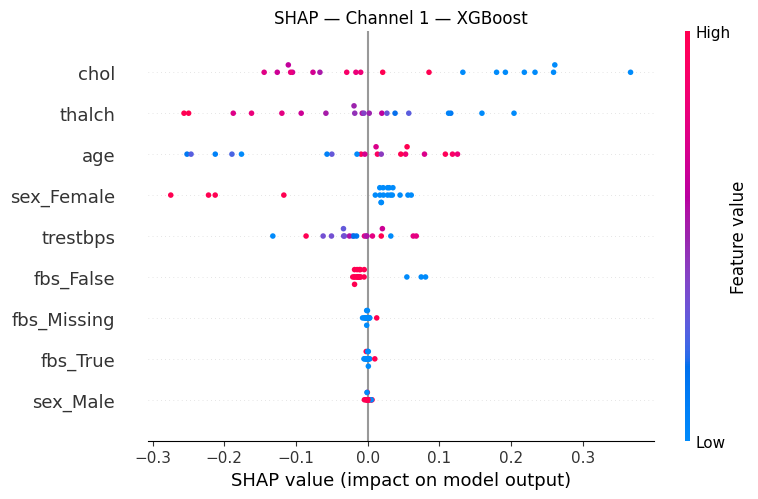

,svm,xgb
chol,0.0847,0.1370
thalch,0.0817,0.0956
age,0.0931,0.0920
sex_Female,0.0389,0.0650
trestbps,0.0183,0.0364
fbs_False,0.0069,0.0220
fbs_Missing,0.0020,0.0025
fbs_True,0.0025,0.0020
sex_Male,0.0391,0.0020


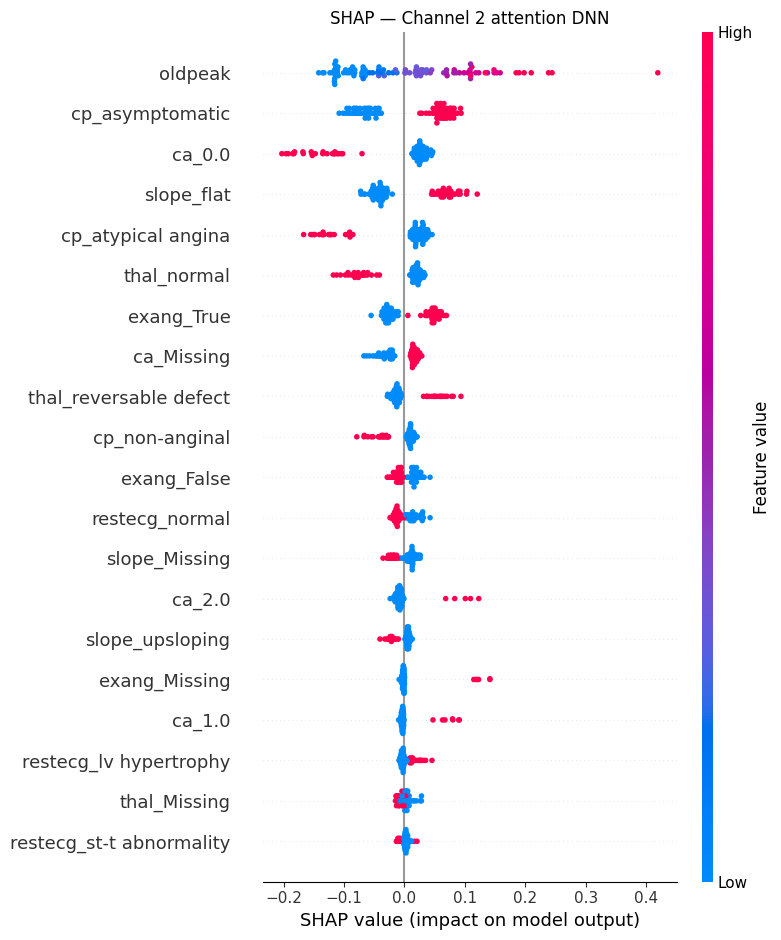

,Feature,Mean_Abs_SHAP
0,oldpeak,0.0883
1,cp_asymptomatic,0.0653
2,ca_0.0,0.0564
3,slope_flat,0.0545
4,cp_atypical angina,0.0466
5,thal_normal,0.0362
6,exang_True,0.0351
7,ca_Missing,0.0234
8,thal_reversable defect,0.0221
9,cp_non-anginal,0.0172


In [23]:
if RUN_SHAP:
    import shap

    def to_2d(sv):
        if isinstance(sv, list): sv = sv[-1]
        sv = np.asarray(sv)
        return sv[:, :, -1] if sv.ndim == 3 else sv

    def dense(a):
        a = a.toarray() if hasattr(a, "toarray") else a
        return np.asarray(a, dtype=float)

    def shap_plot(values, data, names, title, fname):
        plt.figure()
        shap.summary_plot(values, data, feature_names=names, show=False)
        plt.title(title); plt.tight_layout()
        plt.savefig(OUTPUT_DIR / fname, dpi=300, bbox_inches="tight"); plt.show()

    X1_all = X_train[CH1_FEATURES]
    bg1  = X1_all.sample(50, random_state=SEED)
    exp1 = X1_all.sample(100, random_state=7).iloc[:20]

    importance = {}
    for key, title in [("svm", "Channel 1 — SVM"), ("xgb", "Channel 1 — XGBoost")]:
        pipe = main["ch1"].named_estimators_[key]
        pre, mdl = pipe.named_steps["preprocessor"], pipe.named_steps["model"]
        names = get_feature_names(pre, CH1_NUM, CH1_CAT)
        bg, ex = dense(pre.transform(bg1)), dense(pre.transform(exp1))
        sv = to_2d(shap.KernelExplainer(mdl.predict_proba, bg).shap_values(ex, nsamples=100))
        shap_plot(sv, ex, names, f"SHAP — {title}", f"shap_channel1_{key}.png")
        importance[key] = pd.Series(np.abs(sv).mean(axis=0), index=names)

    ch1_importance = pd.DataFrame(importance).sort_values("xgb", ascending=False)
    display(ch1_importance.round(4))

    # ---- Channel 2 (trained DNN) ----
    ch2_names = get_feature_names(main["ch2_pre"], CH2_NUM, CH2_CAT)
    Xp = main["ch2_train_processed"]
    rng = np.random.default_rng(SEED)
    bg2 = Xp[rng.choice(len(Xp), 50, replace=False)]
    ex2 = Xp[rng.choice(len(Xp), 100, replace=False)]
    try:
        sv2 = to_2d(shap.GradientExplainer(main["ch2"], bg2).shap_values(ex2))
    except Exception as err:
        print("GradientExplainer failed (", type(err).__name__, ") -> using KernelExplainer")
        f = lambda z: main["ch2"].predict(z, verbose=0).ravel()
        sv2 = to_2d(shap.KernelExplainer(f, bg2).shap_values(ex2, nsamples=100))
    shap_plot(sv2, ex2, ch2_names, "SHAP — Channel 2 attention DNN", "shap_channel2.png")
    ch2_importance = (pd.DataFrame({"Feature": ch2_names, "Mean_Abs_SHAP": np.abs(sv2).mean(axis=0)})
                      .sort_values("Mean_Abs_SHAP", ascending=False).reset_index(drop=True))
    display(ch2_importance.head(10).round(4))
else:
    print("SHAP skipped.")

## Step 14 — Save results

In [25]:
baseline_cv.to_csv(OUTPUT_DIR / "baseline_cv_results.csv", index=False)
test_results.to_csv(OUTPUT_DIR / "test_results.csv", index=False)
if RUN_ABLATION:  ablation_df.to_csv(OUTPUT_DIR / "preprocessing_ablation.csv", index=False)
if RUN_NESTED_CV: nested_df.to_csv(OUTPUT_DIR / "nested_cv_folds.csv")
if RUN_SHAP:
    ch1_importance.to_csv(OUTPUT_DIR / "shap_channel1_importance.csv")
    ch2_importance.to_csv(OUTPUT_DIR / "shap_channel2_importance.csv", index=False)
print("Saved to:", OUTPUT_DIR.resolve())

Saved to: /kaggle/working
